In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"

In [3]:
movie = tifffile.imread(path)[:, ::2, ::2]

In [4]:
# Convert the data type to float32
movie = movie.astype(np.float32)

# Create the ImageWidget
iw_movie = fpl.ImageWidget(movie)

rs = iw_movie.managed_graphics[0]

# Show the widget
iw_movie.show()

RFBOutputContext()

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [5]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [28]:
print (X.shape)
n_pixels = X.shape[0]
n_time_steps = X.shape[1]
X_past = np.zeros((n_pixels,int(n_time_steps/2)))
X_future = np.zeros((n_pixels,int(n_time_steps/2)))

for col in range(0,int(n_time_steps/2)):
    X_past[:,col] = X[:,2*col]
    X_future[:,col] = X[:,2*col+1]

print (X)
print (X_past)
print (X_future)

(1200, 2000)
[[1534.  844. 1066. ...  989. 1830. 1270.]
 [ 939.  999. 1038. ... 1324. 1619. 1594.]
 [ 829.  825. 1175. ... 1346. 1153. 1652.]
 ...
 [ 447.  296.  533. ...  664.  726. 1077.]
 [ 998.  582.  368. ...  820.  681.  662.]
 [1023. 1127.  647. ... 1214.  909. 1217.]]
[[1534. 1066.  714. ... 1089. 1015. 1830.]
 [ 939. 1038.  791. ... 1131. 1068. 1619.]
 [ 829. 1175.  925. ... 1392. 1120. 1153.]
 ...
 [ 447.  533.  437. ...  617.  575.  726.]
 [ 998.  368.  926. ...  882.  582.  681.]
 [1023.  647.  839. ... 1180.  985.  909.]]
[[ 844.  815.  897. ... 1021.  989. 1270.]
 [ 999. 1060.  821. ... 1120. 1324. 1594.]
 [ 825. 1242.  493. ...  988. 1346. 1652.]
 ...
 [ 296.  385.  257. ...  542.  664. 1077.]
 [ 582.  426.  666. ...  987.  820.  662.]
 [1127.  723.  854. ... 1135. 1214. 1217.]]


In [19]:
n_pixels = X.T.shape[0]
n_time_steps = X.T.shape[1]
X_past_T = np.zeros((n_pixels,int(n_time_steps/2)))
X_future_T = np.zeros((n_pixels,int(n_time_steps/2)))

for col in range(0,int(n_time_steps/2)):
    X_past_T[:,col] = X.T[:,2*col]
    X_future_T[:,col] = X.T[:,2*col+1]

In [20]:
def whiten_matrix(X, epsilon=1e-5):
    """
    Performs whitening on a given data matrix.

    Whitening, or decorrelation, is a data preprocessing technique that
    transforms a dataset such that its features become uncorrelated and
    have unit variance. The covariance matrix of the whitened data is the
    identity matrix.

    This implementation uses the Eigendecomposition method (PCA whitening).

    Parameters:
    - X (np.ndarray): The input data matrix, where each row is a sample
                      and each column is a feature. Shape (n_samples, n_features).
    - epsilon (float): A small constant added to the eigenvalues to ensure
                       numerical stability (avoids division by zero).

    Returns:
    - X_whitened (np.ndarray): The whitened data matrix with the same shape as X.
    """
    # 1. Center the data by subtracting the mean of each feature.
    # The mean is calculated along the columns (axis=0).
    X_mean = np.mean(X, axis=0)
    X_centered = X - X_mean

    # 2. Compute the covariance matrix of the centered data.
    # `rowvar=False` indicates that columns represent features, while rows are observations.
    cov_matrix = np.cov(X_centered, rowvar=False)

    # 3. Perform eigendecomposition of the covariance matrix.
    # `eigh` is used for symmetric matrices like the covariance matrix.
    # It returns eigenvalues in ascending order and corresponding eigenvectors.
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # 4. Construct the whitening matrix.
    # This matrix is used to project the data into a new space where it is decorrelated.
    # It's formed by the eigenvectors and the inverse square root of the eigenvalues.
    # Epsilon is added to the eigenvalues to prevent division by zero for features
    # with zero variance.
    W = np.dot(eigenvectors, np.diag(1.0 / np.sqrt(eigenvalues + epsilon)))

    # 5. Transform the centered data to get the whitened data.
    # This is done by projecting the centered data onto the whitening matrix.
    X_whitened = np.dot(X_centered, W)

    return X_whitened, X_mean, W

In [21]:
X_past_whitened, X_past_mean, X_past_whitening_matrix = whiten_matrix(X_past)
X_future_whitened, X_future_mean, X_future_whitening_matrix = whiten_matrix(X_future)

# Verify the result
# The covariance matrix of the whitened data should be close to the identity matrix.
whitened_cov = np.cov(X_past_whitened, rowvar=False)
print("\nCovariance matrix of the whitened data:")
print(whitened_cov)
print("(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)")


Covariance matrix of the whitened data:
[[ 9.99999978e-01  1.24401647e-13  4.38444573e-14 ... -3.48011861e-15
  -3.79272186e-16  8.00175420e-15]
 [ 1.24401647e-13  9.99999981e-01  3.97465399e-14 ... -4.46681891e-16
  -9.01882590e-16 -8.26694843e-16]
 [ 4.38444573e-14  3.97465399e-14  9.99999982e-01 ... -1.73154050e-15
   9.94941318e-16  4.50163491e-15]
 ...
 [-3.48011861e-15 -4.46681891e-16 -1.73154050e-15 ...  1.00000000e+00
  -1.18374405e-15  8.17805651e-16]
 [-3.79272186e-16 -9.01882590e-16  9.94941318e-16 ... -1.18374405e-15
   1.00000000e+00 -2.60749628e-16]
 [ 8.00175420e-15 -8.26694843e-16  4.50163491e-15 ...  8.17805651e-16
  -2.60749628e-16  1.00000000e+00]]
(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)


In [22]:
X_past_whitened_T, X_past_mean_T, X_past_whitening_matrix_T = whiten_matrix(X_past_T)
X_future_whitened_T, X_future_mean_T, X_future_whitening_matrix_T = whiten_matrix(X_future_T)

# Verify the result
# The covariance matrix of the whitened data should be close to the identity matrix.
whitened_cov = np.cov(X_past_whitened_T, rowvar=False)
print("\nCovariance matrix of the whitened data:")
print(whitened_cov)
print("(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)")


Covariance matrix of the whitened data:
[[ 9.99999999e-01  5.29796872e-15 -6.62912557e-16 ... -1.06501434e-15
   3.17460471e-16 -5.41171243e-16]
 [ 5.29796872e-15  9.99999999e-01 -8.97508958e-17 ...  1.20630536e-16
  -3.32344901e-16  2.76805981e-16]
 [-6.62912557e-16 -8.97508958e-17  9.99999999e-01 ...  4.30315558e-16
  -2.01050893e-16 -1.02724788e-15]
 ...
 [-1.06501434e-15  1.20630536e-16  4.30315558e-16 ...  1.00000000e+00
  -2.13269455e-17  2.45259874e-16]
 [ 3.17460471e-16 -3.32344901e-16 -2.01050893e-16 ... -2.13269455e-17
   1.00000000e+00 -1.17653650e-15]
 [-5.41171243e-16  2.76805981e-16 -1.02724788e-15 ...  2.45259874e-16
  -1.17653650e-15  1.00000000e+00]]
(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)


In [23]:
X_past_unwhitened = X_past_whitened @ np.linalg.pinv(X_past_whitening_matrix) + X_past_mean
print (X_past_unwhitened)
print (X_past)

[[1534. 1066.  714. ... 1089. 1015. 1830.]
 [ 939. 1038.  791. ... 1131. 1068. 1619.]
 [ 829. 1175.  925. ... 1392. 1120. 1153.]
 ...
 [ 447.  533.  437. ...  617.  575.  726.]
 [ 998.  368.  926. ...  882.  582.  681.]
 [1023.  647.  839. ... 1180.  985.  909.]]
[[1534. 1066.  714. ... 1089. 1015. 1830.]
 [ 939. 1038.  791. ... 1131. 1068. 1619.]
 [ 829. 1175.  925. ... 1392. 1120. 1153.]
 ...
 [ 447.  533.  437. ...  617.  575.  726.]
 [ 998.  368.  926. ...  882.  582.  681.]
 [1023.  647.  839. ... 1180.  985.  909.]]


In [24]:
Y = np.vstack((X_past_whitened, X_future_whitened))
Y_unwhitened = np.vstack((X_past, X_future))
print (Y.shape)

whitened_cov = np.cov(Y, rowvar=False)
print("\nCovariance matrix of the whitened data:")
print(whitened_cov.shape)
print(whitened_cov)
print("(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)")

(2400, 1000)

Covariance matrix of the whitened data:
(1000, 1000)
[[ 9.99583139e-01 -2.59944907e-14  4.23989499e-14 ...  6.37718769e-17
  -2.33725317e-15 -1.57125019e-15]
 [-2.59944907e-14  9.99583141e-01  2.46289025e-14 ...  4.76391656e-15
  -1.02090537e-15 -7.55414442e-15]
 [ 4.23989499e-14  2.46289025e-14  9.99583142e-01 ...  2.22155674e-15
  -1.55625593e-15 -5.89589051e-16]
 ...
 [ 6.37718769e-17  4.76391656e-15  2.22155674e-15 ...  9.99583160e-01
  -6.29388626e-16  9.03357792e-16]
 [-2.33725317e-15 -1.02090537e-15 -1.55625593e-15 ... -6.29388626e-16
   9.99583160e-01 -1.42167784e-16]
 [-1.57125019e-15 -7.55414442e-15 -5.89589051e-16 ...  9.03357792e-16
  -1.42167784e-16  9.99583160e-01]]
(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)


In [25]:
Y_T = np.vstack((X_past_whitened_T, X_future_whitened_T))
Y_unwhitened_T = np.vstack((X_past_T, X_future_T))
print (Y_T.shape)

whitened_cov = np.cov(Y_T, rowvar=False)
print("\nCovariance matrix of the whitened data:")
print(whitened_cov.shape)
print(whitened_cov)
print("(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)")

(4000, 600)

Covariance matrix of the whitened data:
(600, 600)
[[ 9.99749937e-01  4.03778036e-15 -1.79368065e-15 ... -5.38592815e-17
  -4.64855572e-16 -4.63745071e-16]
 [ 4.03778036e-15  9.99749937e-01  2.30984135e-17 ...  4.90286037e-17
  -4.63911646e-16 -4.36648855e-16]
 [-1.79368065e-15  2.30984135e-17  9.99749937e-01 ...  4.15938018e-16
   1.35925280e-16 -7.76017854e-16]
 ...
 [-5.38592815e-17  4.90286037e-17  4.15938018e-16 ...  9.99749937e-01
   1.83010507e-16  1.77680104e-17]
 [-4.64855572e-16 -4.63911646e-16  1.35925280e-16 ...  1.83010507e-16
   9.99749937e-01 -7.96006866e-16]
 [-4.63745071e-16 -4.36648855e-16 -7.76017854e-16 ...  1.77680104e-17
  -7.96006866e-16  9.99749937e-01]]
(Note that diagonal elements are ~1.0 and off-diagonal elements are ~0.0)


In [26]:
YYT = Y @ Y.T
print (YYT.shape)
YTY = Y_T @ Y_T.T
print (YTY.shape)

(2400, 2400)
(4000, 4000)


In [27]:
YYT_eigenvalues, YYT_eigenvectors = np.linalg.eig(YYT)
YYT_eigenvalues = np.real(YYT_eigenvalues)
YYT_eigenvectors = np.real(YYT_eigenvectors)
sorted_indices = np.argsort(YYT_eigenvalues)[::-1]
YYT_eigenvalues = YYT_eigenvalues[sorted_indices]
YYT_eigenvectors = YYT_eigenvectors[:, sorted_indices]
print (YYT_eigenvalues.shape)
print (YYT_eigenvalues[:5])

(2400,)
[2398. 2398. 2398. 2398. 2398.]


In [29]:
YTY_eigenvalues, YTY_eigenvectors = np.linalg.eig(YTY)
YTY_eigenvalues = np.real(YTY_eigenvalues)
YTY_eigenvectors = np.real(YTY_eigenvectors)
sorted_indices = np.argsort(YTY_eigenvalues)[::-1]
YTY_eigenvalues = YTY_eigenvalues[sorted_indices]
YTY_eigenvectors = YTY_eigenvectors[:, sorted_indices]
print (YTY_eigenvalues.shape)
print (YTY_eigenvalues[:5])

(4000,)
[3998.         3998.         3997.99999999 3997.99999999 3997.99999999]


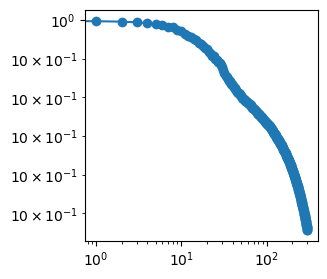

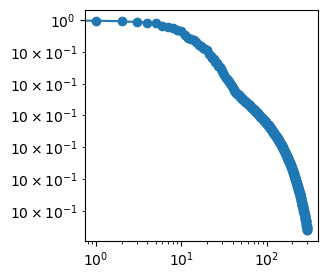

In [30]:
fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(YYT_eigenvalues[:300] / YYT_eigenvalues.max(),'o-')
ax.set_yscale('log')
ax.set_xscale('log')
plt.show()

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(YTY_eigenvalues[:300] / YTY_eigenvalues.max(),'o-')
ax.set_yscale('log')
ax.set_xscale('log')
plt.show()

n_rows = 3
n_cols = 4
K_truncate = n_rows * n_cols

In [31]:
U_k = np.abs(YYT_eigenvectors[:,:K_truncate])
print (U_k.shape)
V_k = np.abs(YTY_eigenvectors[:,:K_truncate])
print (V_k.shape)

(2400, 12)
(4000, 12)


In [32]:
print (Y_unwhitened.shape)
print (Y_unwhitened_T.shape)

(2400, 1000)
(4000, 600)


In [17]:
lr = 0.5

# Y_unwhitened = S @ T
residual = np.zeros_like(Y_unwhitened)

for iteration in range(0,20):
    T = U_k.T @ Y_unwhitened
    T = np.maximum(0, T)
    
    S = Y_unwhitened @ np.linalg.pinv(T)
    S = np.maximum(0, S)
    
    T = np.linalg.pinv(S) @ Y_unwhitened
    T = np.maximum(0, T)

    gradient = np.linalg.pinv(Y_unwhitened.T) @ T.T - U_k
    U_k = U_k + lr * gradient

    error = Y_unwhitened - S @ T
    print (np.linalg.norm(error)/np.linalg.norm(Y_unwhitened))
    residual = error

# for iteration in range(0,20):
#     T = U_k.T @ Y_unwhitened
#     T = np.maximum(0, T)
    
#     S = Y_unwhitened @ np.linalg.pinv(T)
#     S = np.maximum(0, S)

#     gradient = np.linalg.pinv(Y_unwhitened) @ S - V_k
#     V_k = V_k + lr * gradient
    
#     S = Y_unwhitened @ V_k
#     S = np.maximum(0, S)
    
#     T = np.linalg.pinv(S) @ Y_unwhitened
#     T = np.maximum(0, T)

#     gradient = np.linalg.pinv(Y_unwhitened.T) @ T.T - U_k
#     U_k = U_k + lr * gradient

#     error = Y_unwhitened - S @ T
#     print (np.linalg.norm(error)/np.linalg.norm(Y_unwhitened))
    
    

0.38863495589041264
0.34980281148300274
0.32591095087517225
0.2898501258912613
0.25462916765960947
0.2294450614095608
0.2136698212010114
0.20413814939830402
0.19819631993311307
0.19436054474822556
0.19186044305350364
0.19017047229414197
0.18899779486077375
0.18816159127314488
0.18753104114808203
0.18704561380324045
0.18667227527522814
0.18638114810985526
0.18614846105072827
0.18595992328744157


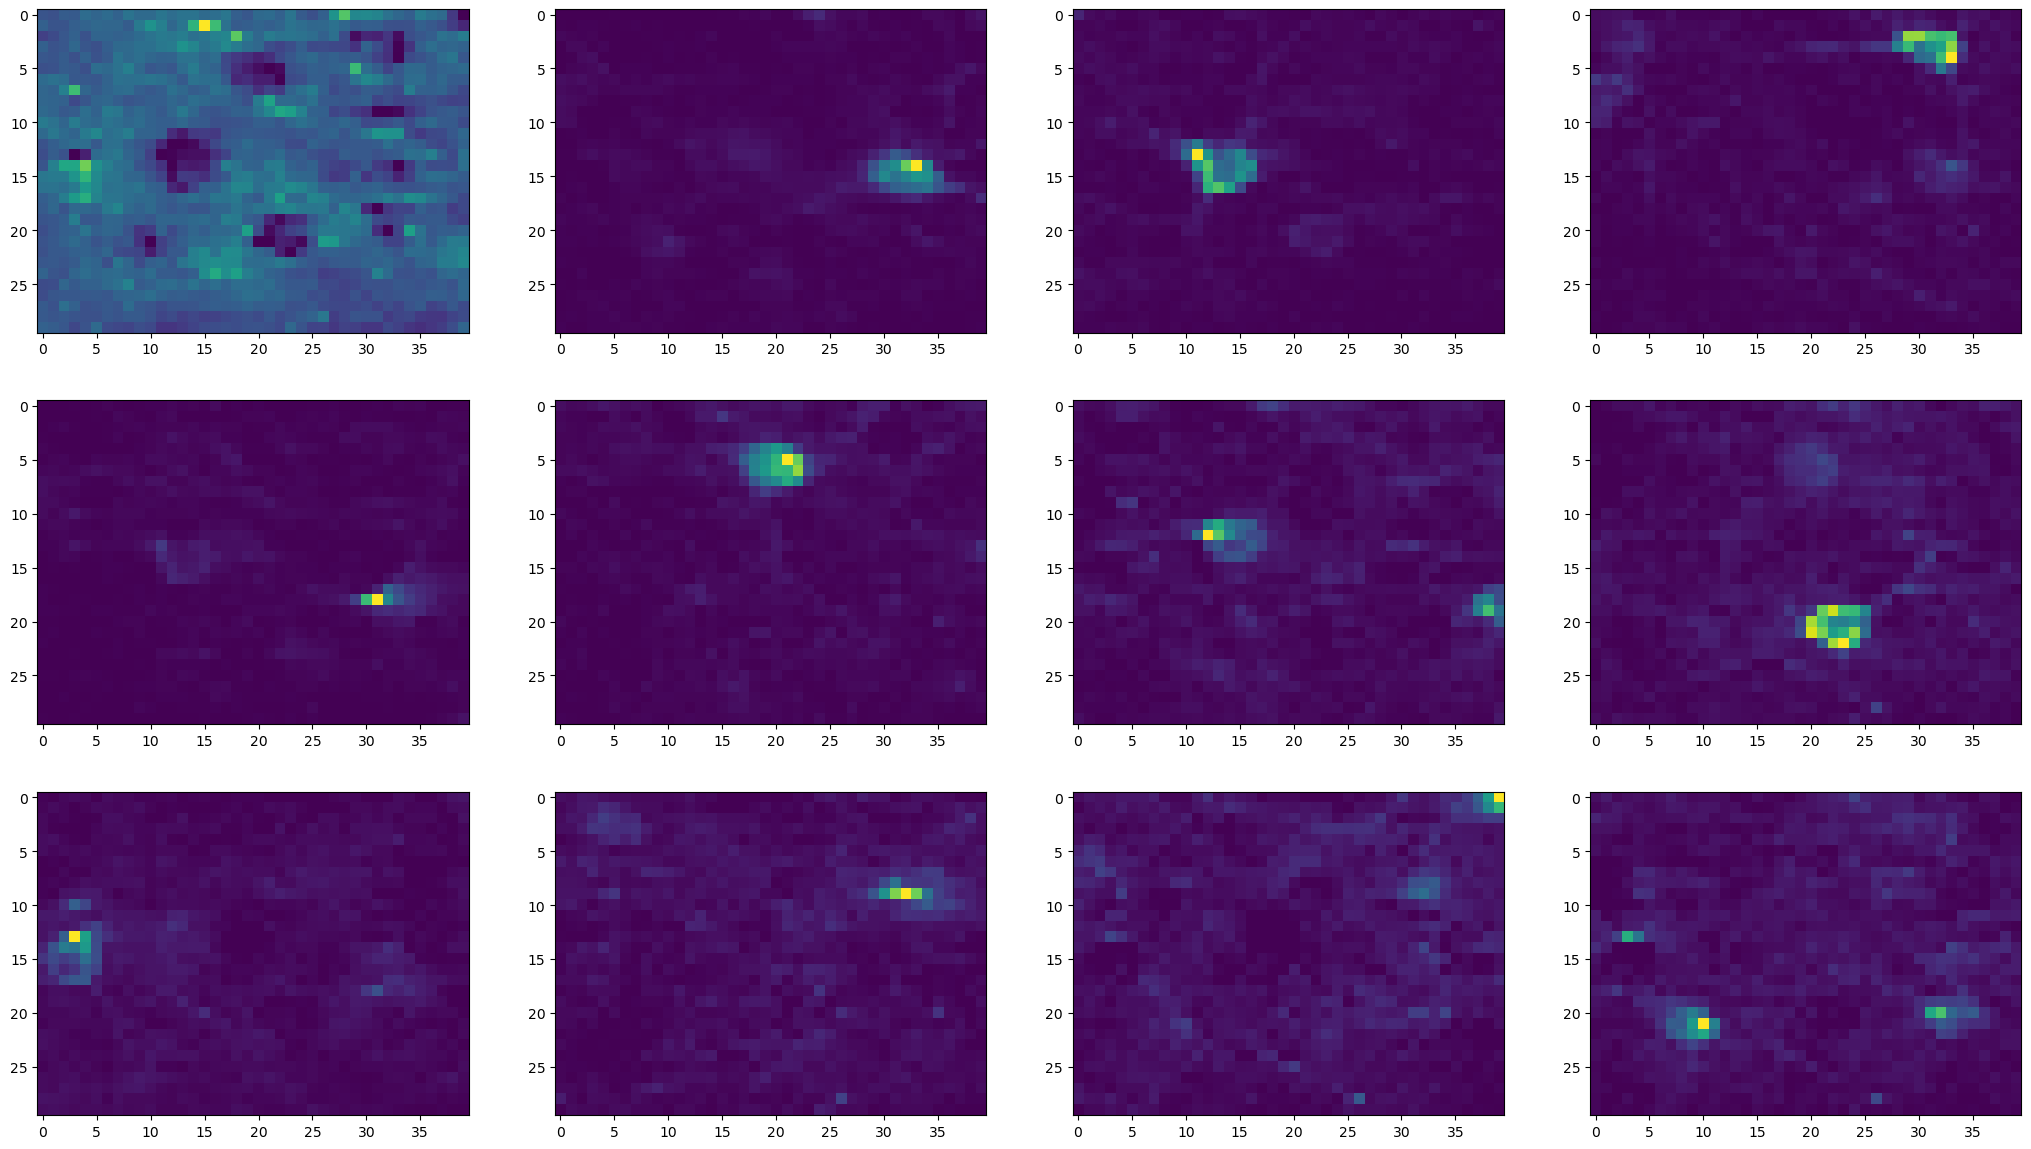

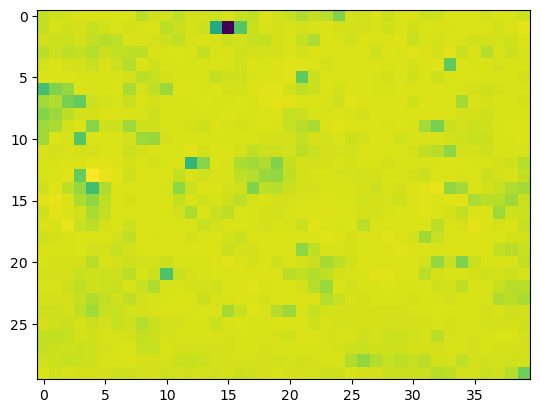

RFBOutputContext()

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [18]:
# unit_array = np.ones_like(T)

movie_array = []
image_array = []
for entry in range(0,K_truncate):
    truncation_matrix = np.zeros((K_truncate,K_truncate))
    truncation_matrix[entry][entry] = 1.
    
    # pastfuture_approx = S @ T
    pastfuture_approx = S @ truncation_matrix @ T
    past_approx = pastfuture_approx[:n_pixels,:]
    future_approx = pastfuture_approx[n_pixels:,:]

    snapshot = unvec.transform(past_approx[:,0])
    image_array += [snapshot]

    movie_approx = unvec.transform(past_approx)
    movie_array += [movie_approx]

fig, ax = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6.4, n_rows * 4.8))
entry = 0
for row in range(0,n_rows):
    for col in range(0,n_cols):
        ax[row][col].imshow(image_array[entry])
        entry += 1
plt.show()

past_residual = residual[:n_pixels,:]
past_residual_mean = unvec.transform(np.mean(past_residual,axis=1))
fig, ax = plt.subplots()
ax.imshow(past_residual_mean)
plt.show()

iw_movie = fpl.ImageWidget(movie_array[7])
rs = iw_movie.managed_graphics[0]
iw_movie.show()